# Federated vs centralized: accuracy, cost and per-hospital fairness

Both approaches use the same data, model, hyperparameters and seeds (42 to 46). Federated =
FedAvg with Flower, 8 rounds x 1 local epoch, five hospitals. Centralized = one model on the
pooled training data, 8 epochs. **Both were run on the same machine**, so the timing is comparable;
the centralized numbers come from `results/centralized_seeds_mac.json`, not the teammate's Windows run.

All differences below are **federated minus centralized**. Significance comes from a *paired
bootstrap* (`src/compare.py`): each draw resamples patients once and scores both models on the same
rows, then averages over the five seeds. Per-hospital tests use each hospital's own validation set.

In [1]:
import sys, json; sys.path.append("..")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..")
R = ROOT / "results"
FIG = R / "figures"; FIG.mkdir(exist_ok=True)

cen = json.loads((R / "centralized_seeds_mac.json").read_text())
fed = json.loads((R / "federated_seeds.json").read_text())
cmp_ = json.loads((R / "comparison.json").read_text())
runs = [json.loads((R / "federated_runs" / f"seed_{s}.json").read_text()) for s in fed["seeds"]]
part = pd.read_csv(R / "hospital_partition.csv")

BLUE, ORANGE = "#2a78d6", "#eb6834"      # centralized, federated (validated pair)
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.labelcolor": INK, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
    "figure.dpi": 110,
})
print("seeds:", fed["seeds"], "| bootstrap draws:", cmp_["bootstrap_draws"])
print("self-check (retrained / reloaded models reproduce recorded ROC-AUC): max abs diff",
      f"{cmp_['check']['cen']['max_abs_diff']:.1e} (centralized),",
      f"{cmp_['check']['fed']['max_abs_diff']:.1e} (federated)")

seeds: [42, 43, 44, 45, 46] | bootstrap draws: 1000
self-check (retrained / reloaded models reproduce recorded ROC-AUC): max abs diff 3.0e-08 (centralized), 5.4e-08 (federated)


## 1. Headline: global test set (19,773 rows)

In [2]:
def ms(d, m, nd=4): return f"{d['global_test'][m]['mean']:.{nd}f} ± {d['global_test'][m]['std']:.{nd}f}"
rows = []
for m in ["roc_auc", "recall", "precision", "f1", "accuracy"]:
    diff = cmp_["diffs"]["global"].get(m)
    rows.append({
        "metric": m, "centralized": ms(cen, m), "federated": ms(fed, m),
        "diff (fed - cen)": f"{fed['global_test'][m]['mean'] - cen['global_test'][m]['mean']:+.4f}",
        "95% CI (paired bootstrap)": f"[{diff['ci_lo']:+.4f}, {diff['ci_hi']:+.4f}]" if diff else "n/a",
        "p": f"{diff['p']:.3f}" if diff else "n/a",
    })
pd.DataFrame(rows).set_index("metric")

,centralized,federated,diff (fed - cen),95% CI (paired bootstrap),p
metric,,,,,
roc_auc,0.6777 ± 0.0023,0.6696 ± 0.0012,-0.0081,"[-0.0132, -0.0030]",0.001
recall,0.6229 ± 0.0396,0.6405 ± 0.0562,+0.0176,"[+0.0075, +0.0277]",0.002
precision,0.1768 ± 0.0057,0.1709 ± 0.0072,-0.0059,n/a,n/a
f1,0.2750 ± 0.0031,0.2692 ± 0.0041,-0.0059,n/a,n/a
accuracy,0.6271 ± 0.0281,0.6047 ± 0.0418,-0.0223,n/a,n/a


ROC-AUC is the headline metric because it does not depend on the 0.5 threshold. Recall, precision,
F1 and accuracy do, and they swing by several points between seeds (the ± above), so only the
bootstrapped rows (ROC-AUC, recall) carry a significance test.

## 2. Cost: communication and time

In [3]:
r1 = np.mean([r["history"][1]["client_train_seconds_sum"] for r in runs])
rest = np.mean([sum(h["client_train_seconds_sum"] for h in r["history"][2:]) for r in runs])
cost = pd.DataFrame({
    "centralized": {
        "training time (s)": f"{cen['train_seconds']['mean']:.1f} ± {cen['train_seconds']['std']:.1f}",
        "communication": "none (data must be pooled)",
    },
    "federated": {
        "training time (s)": f"{fed['train_seconds']['mean']:.1f} ± {fed['train_seconds']['std']:.1f}",
        "communication": (f"{runs[0]['total_bytes']/1e6:.2f} MB training traffic "
                          f"({runs[0]['total_bytes_with_eval']/1e6:.2f} MB incl. evaluation broadcast)"),
    },
})
display(cost)
print(f"model size {runs[0]['model_bytes']/1e3:.1f} KB; {runs[0]['bytes_per_round']/1e6:.2f} MB per round "
      f"(5 clients x down + up)")
print(f"summed client compute: {fed['client_train_seconds_total']['mean']:.1f} s "
      f"(round 1: {r1:.1f} s of cold start; rounds 2-8: {rest:.1f} s)")

,centralized,federated
training time (s),5.8 ± 0.5,33.8 ± 8.4
communication,none (data must be pooled),4.49 MB training traffic (6.73 MB incl. evalua...


model size 56.1 KB; 0.56 MB per round (5 clients x down + up)
summed client compute: 35.9 s (round 1: 25.8 s of cold start; rounds 2-8: 10.2 s)


Federated wall-clock time is several times the centralized time. Most of the excess is simulation
overhead (Flower + Ray messaging, five worker processes) plus a cold start in round 1, not model
compute. The 4.5 MB is tiny: the model has only 13,825 parameters.

## 3. Convergence of the federated model

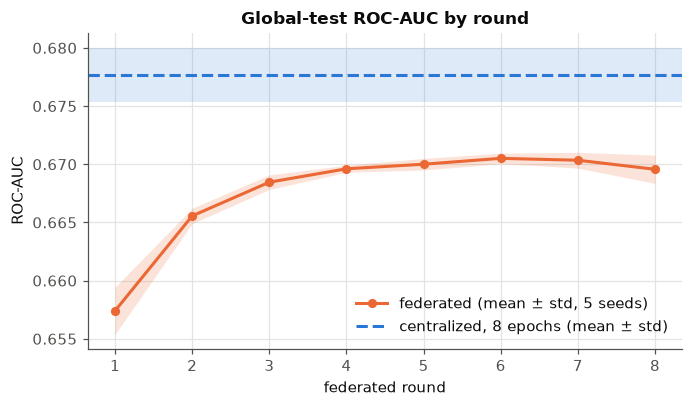

round-1 AUC 0.6574 -> round-3 0.6685 -> round-8 0.6696 | centralized 0.6777


In [4]:
rounds = np.arange(1, runs[0]["rounds"] + 1)
auc = np.array([[h["global_test"]["roc_auc"] for h in r["history"][1:]] for r in runs])   # seeds x rounds
m, s = auc.mean(0), auc.std(0, ddof=1)
cm, cs = cen["global_test"]["roc_auc"]["mean"], cen["global_test"]["roc_auc"]["std"]

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.fill_between(rounds, m - s, m + s, color=ORANGE, alpha=0.18, lw=0)
ax.plot(rounds, m, color=ORANGE, lw=2, marker="o", ms=5, label="federated (mean ± std, 5 seeds)")
ax.axhspan(cm - cs, cm + cs, color=BLUE, alpha=0.15, lw=0)
ax.axhline(cm, color=BLUE, lw=2, ls="--", label="centralized, 8 epochs (mean ± std)")
ax.set(title="Global-test ROC-AUC by round", xlabel="federated round", ylabel="ROC-AUC",
       xticks=rounds)
ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "comparison_convergence.png", dpi=150); plt.show()
print("round-1 AUC", round(m[0], 4), "-> round-3", round(m[2], 4), "-> round-8", round(m[-1], 4),
      "| centralized", round(cm, 4))

The federated model reaches its plateau by round 3 and stays about 0.008 below the centralized
model, so the gap is not just "too few rounds". Matching the centralized budget (8 rounds) is
therefore not what limits it; a rounds sweep would confirm this.

## 4. Per-hospital results

In [5]:
H = range(5)
def sig(p): return "yes" if p < 0.05 else "no"
rows = []
for h in H:
    d = cmp_["diffs"][str(h)]
    a, r = d["roc_auc"], d["recall"]
    rows.append({
        "hospital": h,
        "positive rate": f"{part.loc[h, 'positive_rate']:.1%}",
        "val positives": runs[0]["per_site_val"][str(h)]["n_pos"],
        "AUC centralized": f"{cen['per_site'][str(h)]['roc_auc']['mean']:.3f} ± {cen['per_site'][str(h)]['roc_auc']['std']:.3f}",
        "AUC federated": f"{fed['per_site'][str(h)]['roc_auc']['mean']:.3f} ± {fed['per_site'][str(h)]['roc_auc']['std']:.3f}",
        "AUC diff": f"{a['diff']:+.3f}",
        "95% CI": f"[{a['ci_lo']:+.3f}, {a['ci_hi']:+.3f}]",
        "p": f"{a['p']:.3f}",
        "p < 0.05": sig(a["p"]),
        "p < 0.01 (Bonferroni, 5 sites)": "yes" if a["p"] < 0.01 else "no",
        "recall diff": f"{r['diff']:+.3f} [{r['ci_lo']:+.3f}, {r['ci_hi']:+.3f}]",
    })
site_tbl = pd.DataFrame(rows).set_index("hospital")
site_tbl

,positive rate,val positives,AUC centralized,AUC federated,AUC diff,95% CI,p,p < 0.05,"p < 0.01 (Bonferroni, 5 sites)",recall diff
hospital,,,,,,,,,,
0,22.4%,275,0.616 ± 0.007,0.600 ± 0.001,-0.016,"[-0.034, +0.002]",0.078,no,no,"-0.001 [-0.037, +0.032]"
1,6.8%,179,0.697 ± 0.006,0.690 ± 0.004,-0.006,"[-0.025, +0.009]",0.478,no,no,"+0.013 [-0.024, +0.049]"
2,24.8%,278,0.627 ± 0.007,0.602 ± 0.002,-0.025,"[-0.040, -0.010]",0.001,yes,yes,"+0.001 [-0.030, +0.032]"
3,8.4%,56,0.619 ± 0.015,0.644 ± 0.004,+0.025,"[-0.003, +0.056]",0.078,no,no,"+0.050 [+0.000, +0.103]"
4,4.8%,97,0.665 ± 0.008,0.655 ± 0.003,-0.010,"[-0.029, +0.009]",0.338,no,no,"-0.006 [-0.048, +0.030]"


*val positives* is the number of positive cases in the hospital's validation set. Hospital 3 has only 56
and hospital 4 only 97, so their intervals are wide.

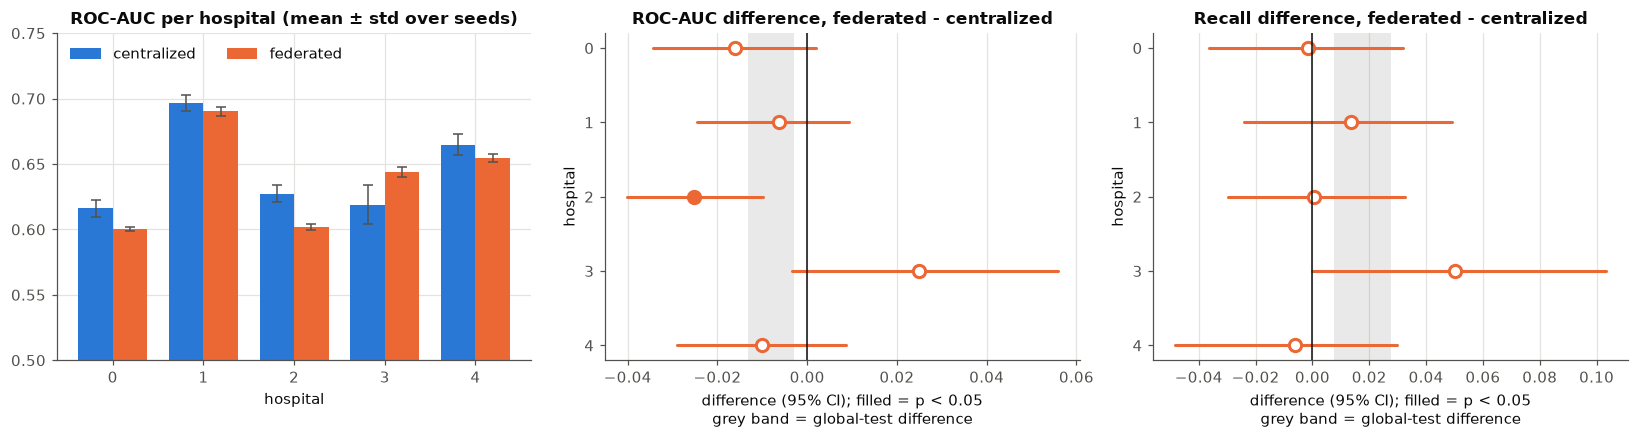

In [6]:
hs = np.arange(5)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.1))

# (a) per-hospital ROC-AUC, both methods
w = 0.38
for off, d, col, lab in [(-w/2, cen, BLUE, "centralized"), (w/2, fed, ORANGE, "federated")]:
    mu = [d["per_site"][str(h)]["roc_auc"]["mean"] for h in hs]
    sd = [d["per_site"][str(h)]["roc_auc"]["std"] for h in hs]
    ax[0].bar(hs + off, mu, w, yerr=sd, capsize=3, color=col, label=lab, error_kw={"lw": 1, "ecolor": MUTED})
ax[0].set(title="ROC-AUC per hospital (mean ± std over seeds)", xlabel="hospital", ylim=(0.5, 0.75), xticks=hs)
ax[0].legend(loc="upper left", ncol=2)

# (b), (c) paired differences with 95% bootstrap intervals
for a, key, title in [(ax[1], "roc_auc", "ROC-AUC difference, federated - centralized"),
                      (ax[2], "recall", "Recall difference, federated - centralized")]:
    for h in hs:
        d = cmp_["diffs"][str(h)][key]
        significant = d["p"] < 0.05
        a.plot([d["ci_lo"], d["ci_hi"]], [h, h], color=ORANGE, lw=2, solid_capstyle="round")
        a.plot(d["diff"], h, "o", ms=8, mfc=ORANGE if significant else "white", mec=ORANGE, mew=2)
    g = cmp_["diffs"]["global"][key]
    a.axvspan(g["ci_lo"], g["ci_hi"], color=MUTED, alpha=0.12, lw=0)
    a.axvline(0, color=INK, lw=1)
    a.set(title=title, xlabel="difference (95% CI); filled = p < 0.05\ngrey band = global-test difference", yticks=hs,
          ylabel="hospital"); a.invert_yaxis(); a.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(FIG / "comparison_per_site.png", dpi=150); plt.show()

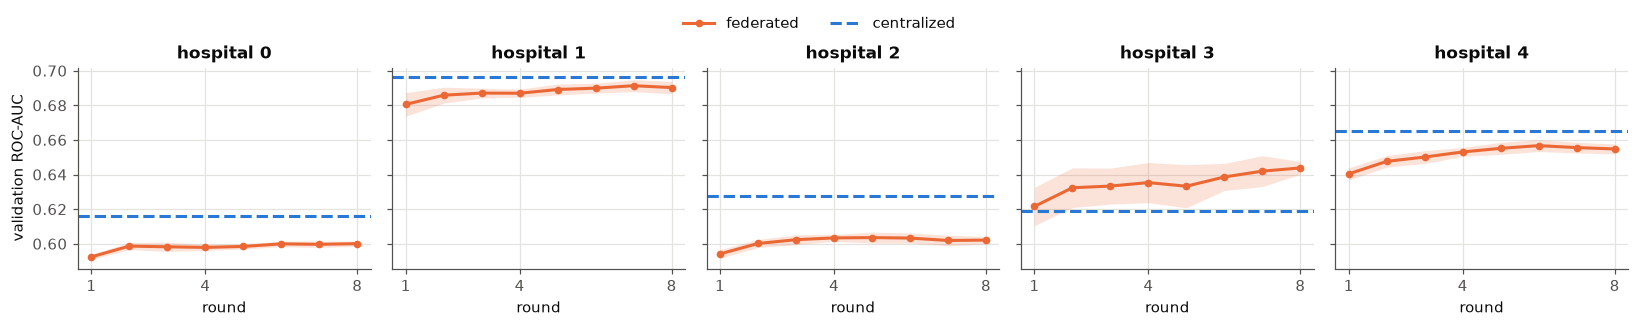

In [7]:
fig, ax = plt.subplots(1, 5, figsize=(15, 3.0), sharey=True)
for h in range(5):
    v = np.array([[x["per_site_val"][str(h)]["roc_auc"] for x in r["history"][1:]] for r in runs])
    mu, sd = v.mean(0), v.std(0, ddof=1)
    c = cen["per_site"][str(h)]["roc_auc"]["mean"]
    ax[h].fill_between(rounds, mu - sd, mu + sd, color=ORANGE, alpha=0.18, lw=0)
    ax[h].plot(rounds, mu, color=ORANGE, lw=2, marker="o", ms=4, label="federated")
    ax[h].axhline(c, color=BLUE, lw=2, ls="--", label="centralized")
    ax[h].set(title=f"hospital {h}", xlabel="round", xticks=[1, 4, 8])
ax[0].set_ylabel("validation ROC-AUC")
hdl, lab = ax[0].get_legend_handles_labels()
fig.legend(hdl, lab, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(rect=(0, 0, 1, 0.92)); plt.savefig(FIG / "comparison_per_site_convergence.png", dpi=150); plt.show()

## 5. Fairness across hospitals

In [8]:
f = cmp_["fairness"]
def fmt(d): return f"{d['diff']:+.3f}  [{d['ci_lo']:+.3f}, {d['ci_hi']:+.3f}]  (p = {d['p']:.2f})"
pd.DataFrame({
    "centralized": {"ROC-AUC gap (max - min)": f"{f['gap_cen']:.3f}", "worst-hospital ROC-AUC": f"{f['worst_site_cen']:.3f}"},
    "federated":   {"ROC-AUC gap (max - min)": f"{f['gap_fed']:.3f}", "worst-hospital ROC-AUC": f"{f['worst_site_fed']:.3f}"},
    "difference, 95% CI": {"ROC-AUC gap (max - min)": fmt(f["gap_diff"]), "worst-hospital ROC-AUC": fmt(f["worst_site_diff"])},
})

,centralized,federated,"difference, 95% CI"
ROC-AUC gap (max - min),0.080,0.090,"+0.010 [-0.049, +0.046] (p = 0.75)"
worst-hospital ROC-AUC,0.616,0.600,"-0.016 [-0.034, +0.036] (p = 0.56)"


The gap and the worst-hospital AUC are computed from seed-averaged AUC per hospital, so the gap here
(0.080) differs a little from the mean of per-seed gaps reported in the results files (0.086).

## 6. Findings

In [9]:
g = cmp_["diffs"]["global"]["roc_auc"]
print(f"GLOBAL    ROC-AUC {g['diff']:+.4f} (95% CI {g['ci_lo']:+.4f} to {g['ci_hi']:+.4f}, p = {g['p']:.3f})")
worse = [h for h in range(5) if cmp_["diffs"][str(h)]["roc_auc"]["p"] < 0.05 and cmp_["diffs"][str(h)]["roc_auc"]["diff"] < 0]
better = [h for h in range(5) if cmp_["diffs"][str(h)]["roc_auc"]["p"] < 0.05 and cmp_["diffs"][str(h)]["roc_auc"]["diff"] > 0]
print("hospitals significantly worse under federated (p < 0.05):", worse or "none")
print("hospitals significantly better under federated (p < 0.05):", better or "none")
print("fairness gap change:", fmt(cmp_["fairness"]["gap_diff"]))

GLOBAL    ROC-AUC -0.0081 (95% CI -0.0132 to -0.0030, p = 0.001)
hospitals significantly worse under federated (p < 0.05): [2]
hospitals significantly better under federated (p < 0.05): none
fairness gap change: +0.010  [-0.049, +0.046]  (p = 0.75)


- **Accuracy cost is small but real.** Federated ROC-AUC is about 0.008 below centralized on the global
  test set (paired 95% CI excludes zero). The curve plateaus by round 3, so more rounds at this learning
  setup are unlikely to close it.
- **Hospital 2 pays for it.** Its AUC drops by about 0.025 and the interval excludes zero even after
  correcting for testing five hospitals. Hospital 2 has the highest positive rate (24.8%).
  *Why* is a hypothesis, not a result: client-specific class weights and local drift on skewed data are
  candidates, and this notebook does not test them.
- **Hospitals 0 and 3 move in opposite directions** (about -0.016 and +0.025) but neither reaches
  p < 0.05, so the data does not establish a real change. Hospitals 1 and 4 show no detectable change.
- **Fairness: no detectable change in the gap.** The ROC-AUC gap is 0.080 centralized vs 0.090 federated,
  but the difference's interval (about -0.05 to +0.05) is far wider than the difference itself. With
  validation sets this small, we cannot say federated training made the spread across hospitals better or
  worse. The only per-hospital loss we can defend is hospital 2's.
- **Recall is higher under federated training** on the global test set (+0.018), but recall depends on the
  fixed 0.5 threshold, and federated clients weight the rare class by their own base rate. Read it as a
  threshold shift, not an improvement in ranking quality; ROC-AUC is the fair comparison.
- **Cost:** 4.5 MB of traffic in total and several times the wall-clock time, mostly overhead.

### Caveats
Hospitals are simulated from one dataset. Per-hospital numbers use small validation sets (hospital 3: 56
positives). Five seeds vary initialisation and batch order but not the data partition, so the intervals
describe sampling noise on this partition only. A local-only baseline (no sharing) is not included yet.